# Takahashi κ (r000, zs1), nside 2048: synthesis results

Synthesis with STL-Dev-MPI (L = 4, kernel 5×5, J = 11, ergodic weights) on 2 H200 at hpc:
gaussianised target, up-sampled to nside 4096, synthesis at 4096, cut back to 2048, histogram matched.

* run 1 (job 1719399): 80 iterations from the garoupe nside 1024 synthesis;
* run 2 (job 1773537): 400 more iterations from run 1.

Data are read from `~/stl-mpi-runs/takahashi_zs1_c2f` (WSL). Run with the `~/stl-deps/venv-cpu` kernel (healpy).

In [29]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Anisotropy helpers of the repository (gnomonic patches, small-scale power ratio).
sys.path.insert(0, str(Path.cwd().parent / "tools"))
from compare_syntheses import anisotropy, gnomonic_patches

%matplotlib inline
CMAP = "RdBu_r"
CMAP = 'viridis'
BASE = Path.home() / "stl-mpi-runs" / "takahashi_zs1_c2f"
FILES = {
    "target": BASE / "takahashi_r000_zs1_nside2048_nested.npy",
    "80 it": BASE / "synth2048_L4_hpcgpu80_nested.npy",
    "480 it": BASE / "synth2048_L4_hpcgpu480_nested.npy",
}
GAUSS = {
    "target": BASE / "prep2048" / "target_gauss_nested.npy",
    "480 it": BASE / "hpc2048" / "1773537" / "synthesis_gauss_nested.npy",
}
REPORTS = {"80 it": BASE / "hpc2048" / "1719399" / "up.json", "480 it": BASE / "hpc2048" / "1773537" / "up.json"}
COLORS = {"target": "#52514e", "80 it": "#2a78d6", "480 it": "#eb6834"}

maps = {k: np.load(p).astype(np.float64) for k, p in FILES.items()}
reps = {k: json.load(open(p)) for k, p in REPORTS.items()}
NSIDE = int(round((maps["target"].size / 12) ** 0.5))
print("nside", NSIDE, "pixels", maps["target"].size)

nside 2048 pixels 50331648


## Run summary

In [30]:
print(f"{'run':8s} {'iter':>5s} {'evals':>6s} {'loss start':>11s} {'loss end':>9s} {'s/eval':>7s} {'hours':>6s} {'GPU mem/rank':>13s}")
for k, r in reps.items():
    mem = max(r["memory_peak_bytes_per_rank"]) / 2**30
    print(f"{k:8s} {r['niter']:5d} {r['evaluations']:6d} {r['loss_first']:11.3e} {r['loss_last']:9.3f} "
          f"{r['seconds_per_evaluation']:7.1f} {r['seconds'] / 3600:6.2f} {mem:10.1f} GiB")

print()
print("residual |S(synth) - S(target)| / sigma per family: rms (max)")
for k, r in reps.items():
    res = r["final_residual_in_ergodic_sigma"]
    print(f"{k:8s}", "  ".join(f"{f} {v['rms_sigma']:.2f} ({v['max_sigma']:.1f})" for f, v in res.items() if f != "mean"))

run       iter  evals  loss start  loss end  s/eval  hours  GPU mem/rank
80 it       80     94   6.390e+04     5.076    67.9   1.77       57.0 GiB
480 it     400    429   5.076e+00     0.772    69.1   8.24       57.0 GiB

residual |S(synth) - S(target)| / sigma per family: rms (max)
80 it    S1 14.03 (41.6)  S2 11.33 (28.3)  S3 4.22 (11.5)  S4 1.87 (15.4)  var 40.86 (40.9)
480 it   S1 3.16 (8.4)  S2 4.21 (11.3)  S3 1.13 (5.1)  S4 0.82 (6.0)  var 2.03 (2.0)


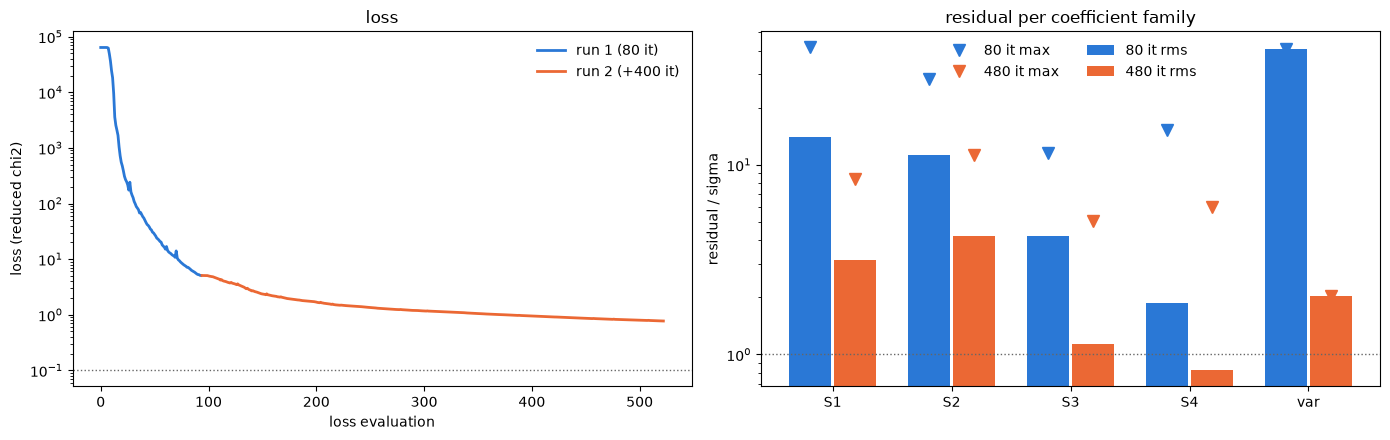

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
h80, h480 = reps["80 it"]["loss_history"], reps["480 it"]["loss_history"]
ax[0].semilogy(np.arange(len(h80)), h80, color=COLORS["80 it"], lw=2, label="run 1 (80 it)")
ax[0].semilogy(len(h80) + np.arange(len(h480)), h480, color=COLORS["480 it"], lw=2, label="run 2 (+400 it)")
ax[0].axhline(0.1, color="0.4", ls=":", lw=1)
ax[0].set(xlabel="loss evaluation", ylabel="loss (reduced chi2)", title="loss")
ax[0].legend(frameon=False)

fams = ["S1", "S2", "S3", "S4", "var"]
for i, k in enumerate(("80 it", "480 it")):
    res = reps[k]["final_residual_in_ergodic_sigma"]
    x = np.arange(len(fams)) + (i - 0.5) * 0.38
    ax[1].bar(x, [res[f]["rms_sigma"] for f in fams], 0.35, color=COLORS[k], label=f"{k} rms")
    ax[1].plot(x, [res[f]["max_sigma"] for f in fams], "v", color=COLORS[k], ms=8, label=f"{k} max")
ax[1].set_yscale("log")
ax[1].axhline(1, color="0.4", ls=":", lw=1)
ax[1].set_xticks(range(len(fams)), fams)
ax[1].set(ylabel="residual / sigma", title="residual per coefficient family")
ax[1].legend(frameon=False, ncol=2)
plt.tight_layout()

## Maps

`healpy.mollview` for the full sky and `healpy.gnomview` for zooms (maps are NESTED: `nest=True`).
Same colour range for the three maps (0.5 and 99.5 percentiles of the target). `show_gnom(lon, lat, size_deg)`
centres a gnomonic view anywhere.

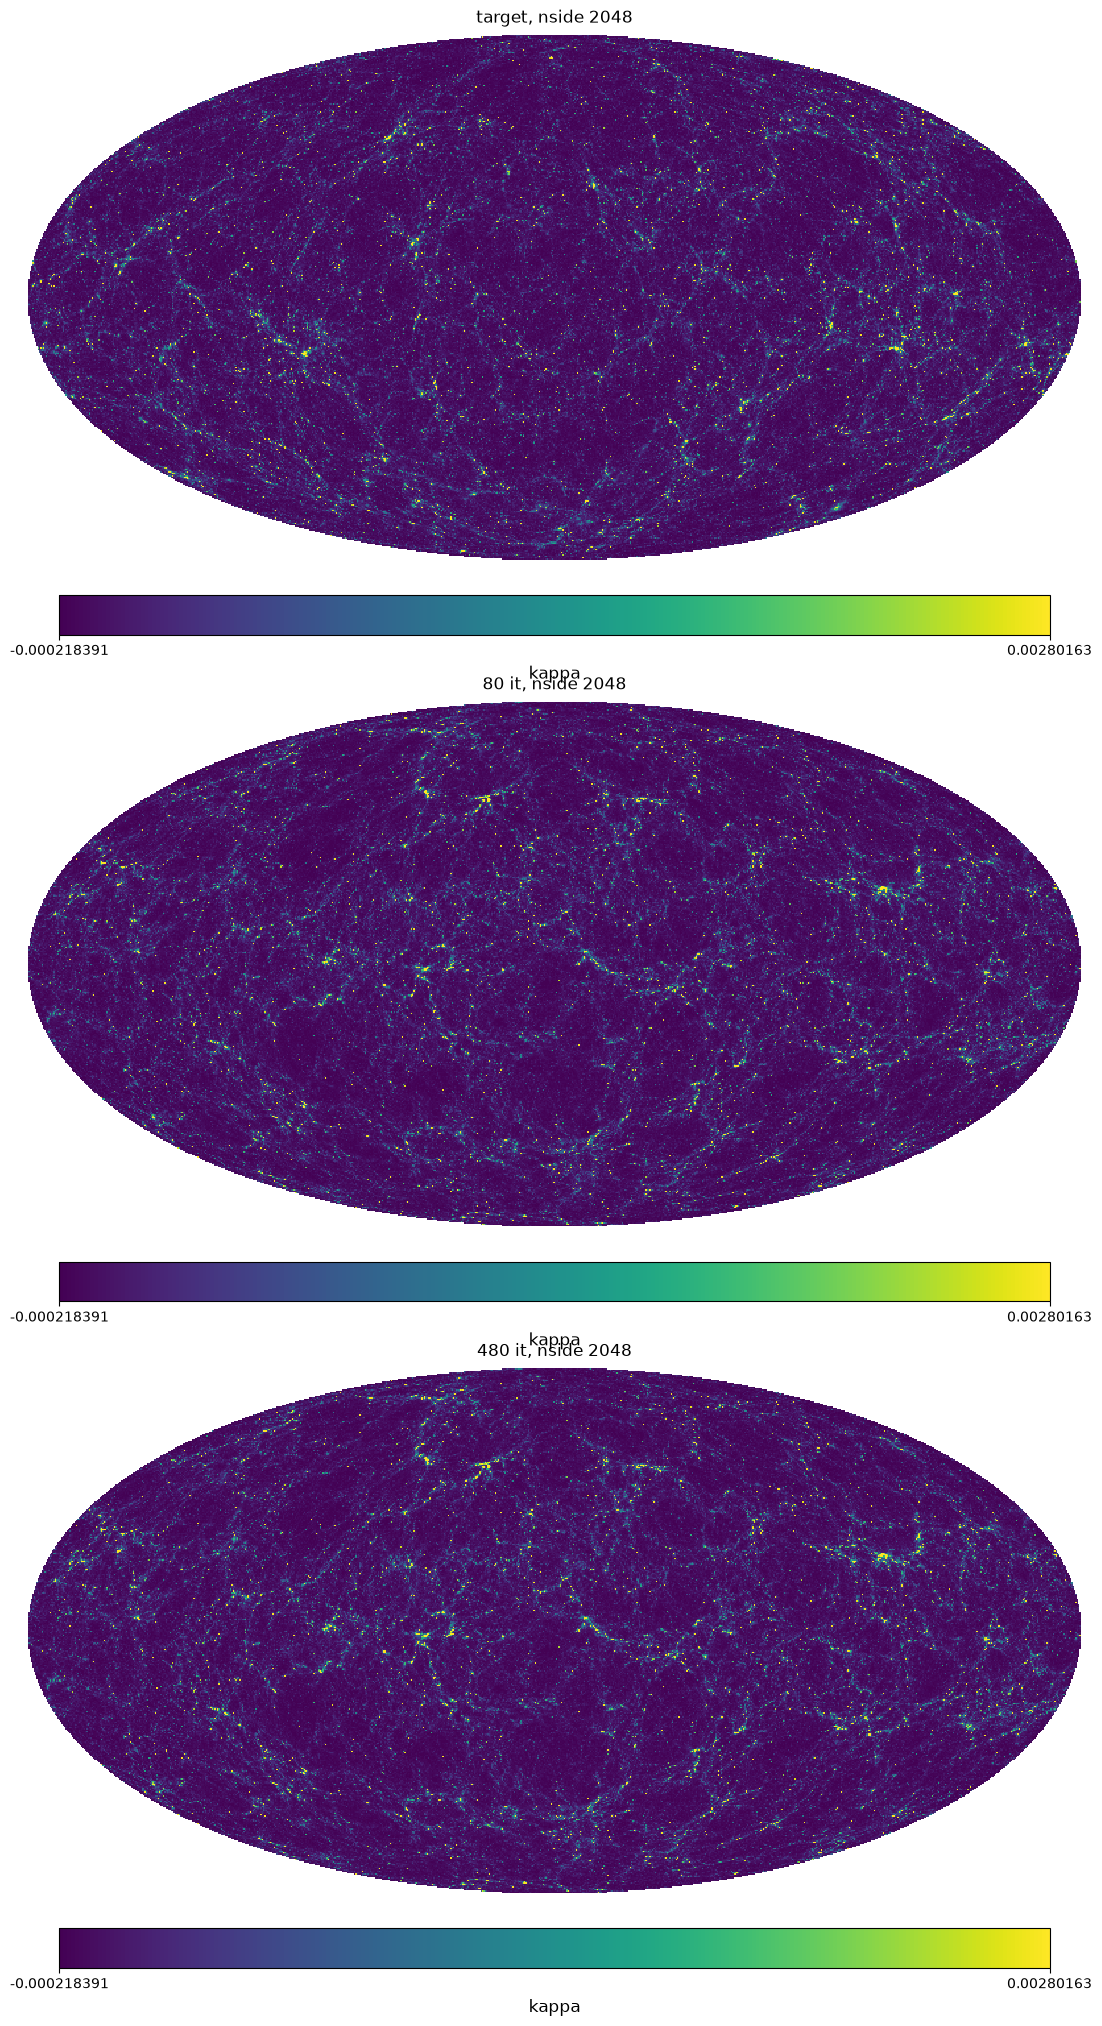

In [32]:
import healpy as hp

VMIN, VMAX = np.percentile(maps["target"], [0.5, 99.5])
fig = plt.figure(figsize=(20, 20))
for i, (k, m) in enumerate(maps.items()):
    hp.mollview(m, nest=True, fig=fig.number, sub=(3, 1, i + 1), title=f"{k}, nside {NSIDE}",
                cmap=CMAP, min=VMIN, max=VMAX, unit="kappa")

In [40]:
cl1=hp.anafast(hp.reorder(maps['target'],n2r=True))
cl2=hp.anafast(hp.reorder(maps['80 it'],n2r=True))
cl3=hp.anafast(hp.reorder(maps['480 it'],n2r=True))

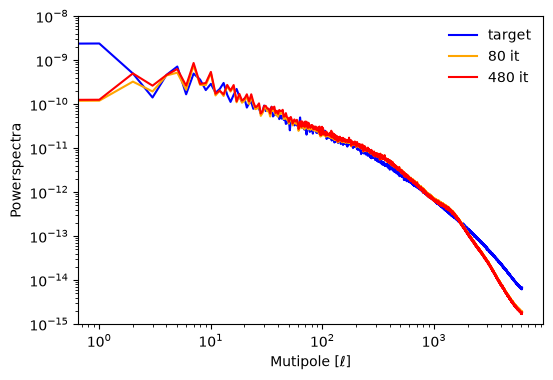

In [49]:
plt.figure(figsize=(6,4))
plt.plot(cl1,color='b',label='target')
plt.plot(cl2,color='orange',label='80 it')
plt.plot(cl3,color='r',label='480 it')
plt.xscale('log')
plt.yscale('log')
plt.ylim(1e-15,1e-8)
plt.xlabel('Mutipole [$\ell$]')
plt.ylabel('Powerspectra')
plt.legend(frameon=0)

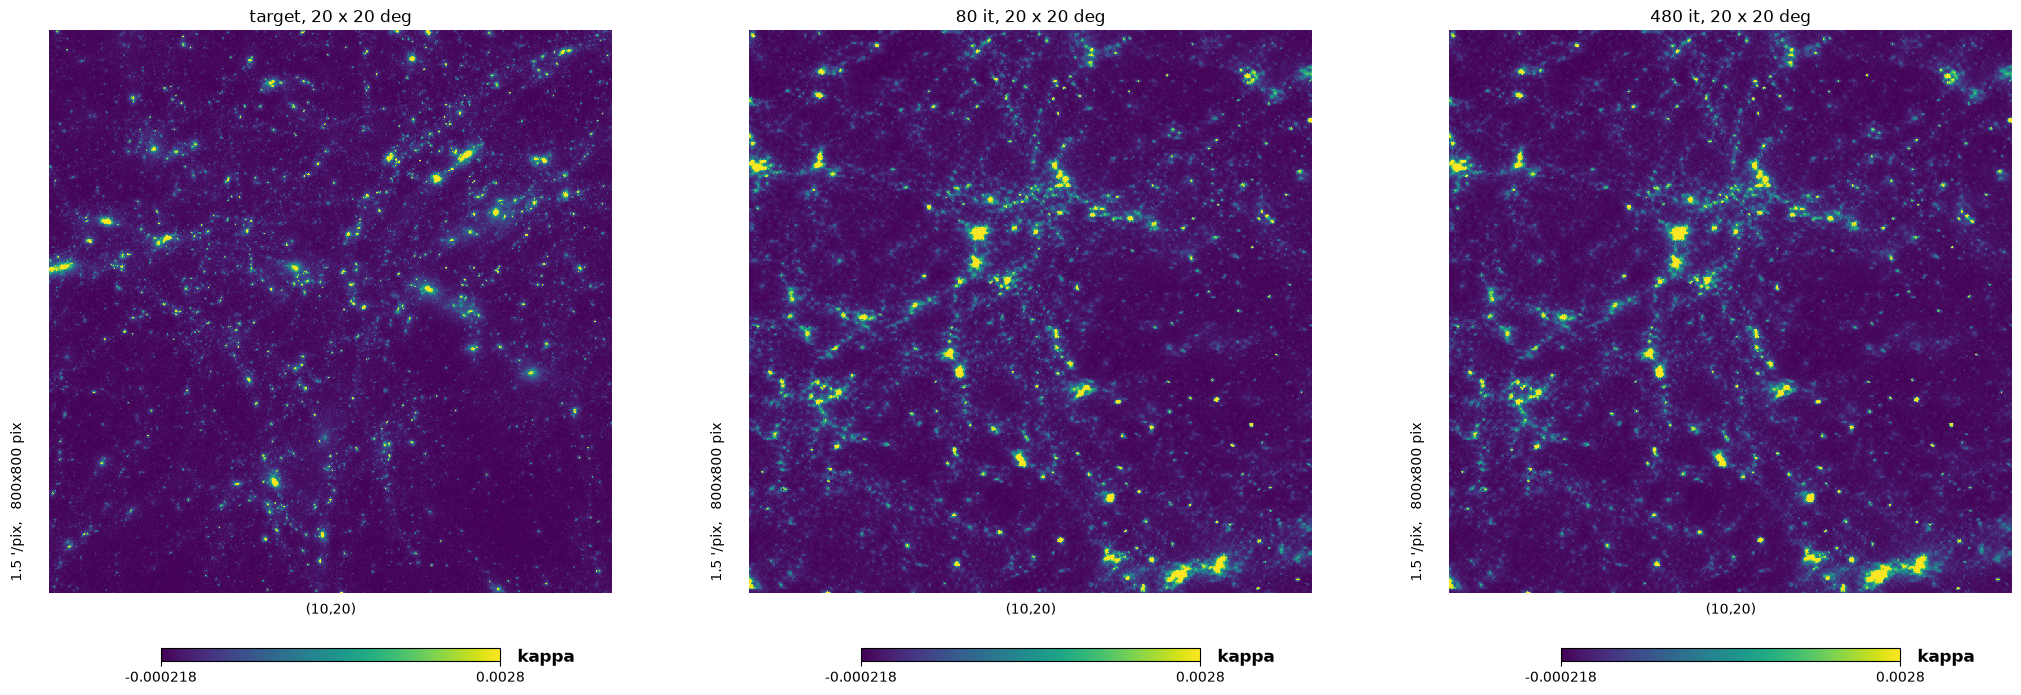

In [35]:
def show_gnom(lon, lat, size_deg, xsize=800):
    """Gnomonic views of the three maps centred on (lon, lat) in degrees, size_deg on a side."""
    reso = size_deg * 60.0 / xsize  # arcmin per screen pixel
    fig = plt.figure(figsize=(21, 7))
    for i, (k, m) in enumerate(maps.items()):
        hp.gnomview(m, nest=True, rot=(lon, lat), xsize=xsize, reso=reso, fig=fig.number, sub=(1, 3, i + 1),
                    title=f"{k}, {size_deg:g} x {size_deg:g} deg", cmap=CMAP, min=VMIN, max=VMAX, unit="kappa")


show_gnom(10.0, 20.0, 20.0)

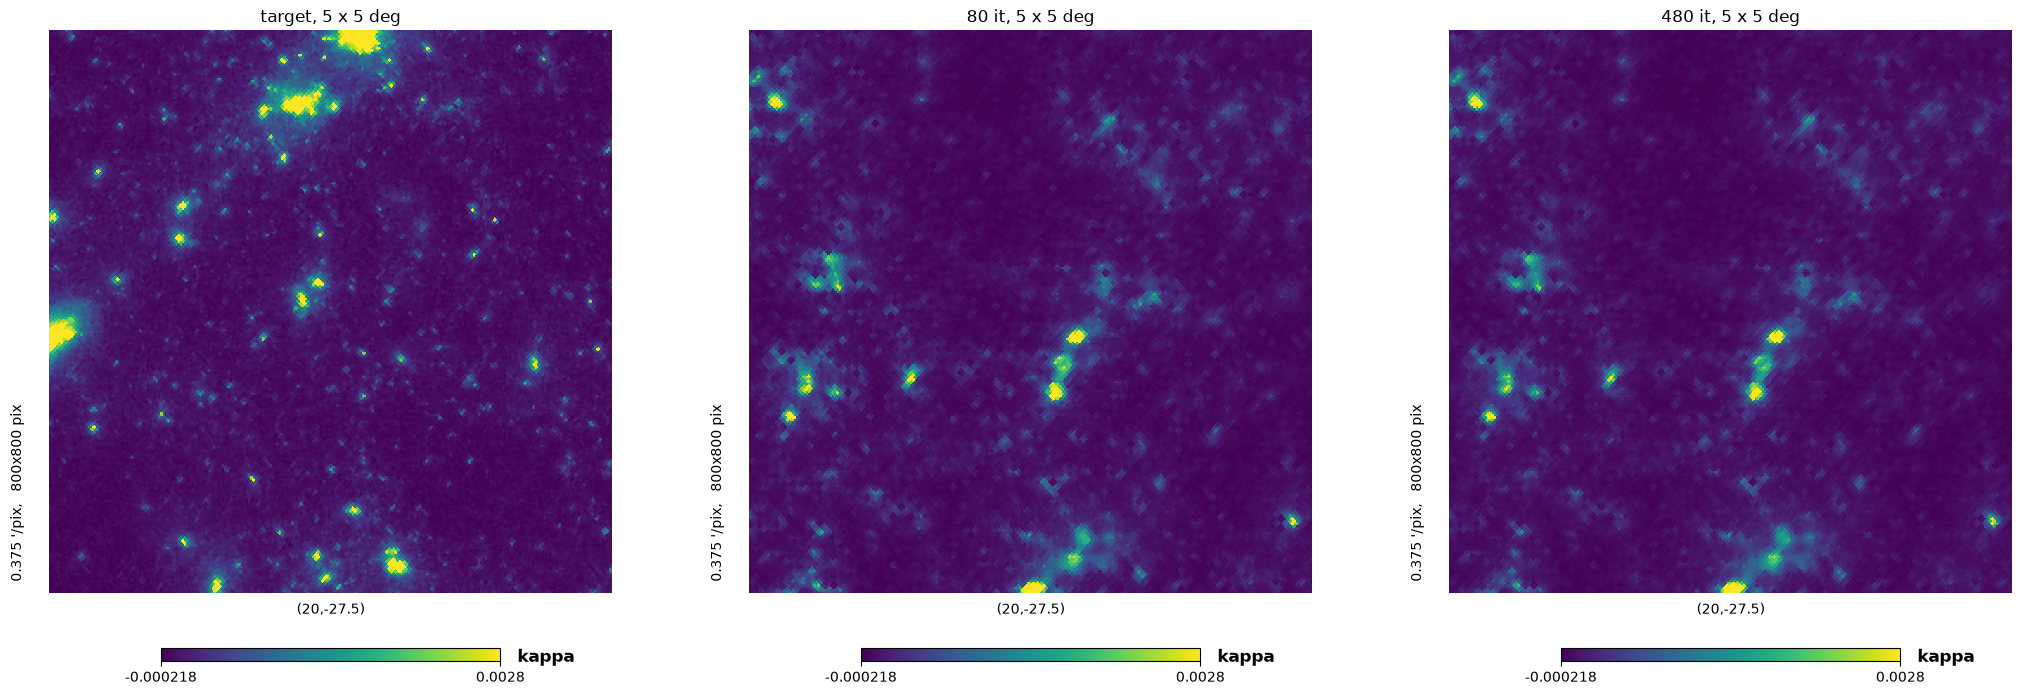

In [36]:
show_gnom(20.0, -27.5, 5.0)  # pixel size at nside 2048: 1.7 arcmin

## Pixel histograms

Identical by construction (final histogram matching).

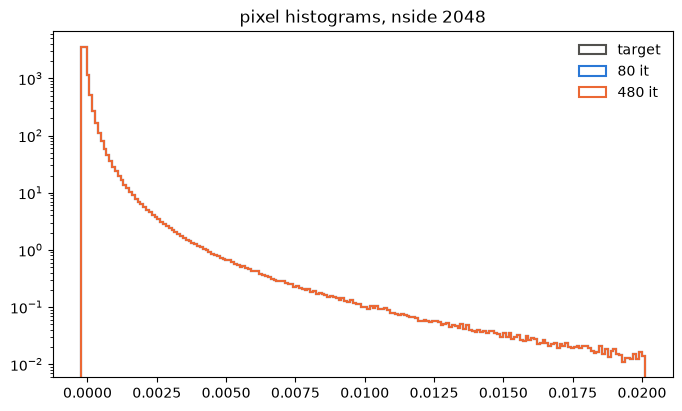

In [19]:
bins = np.linspace(np.percentile(maps["target"], 0.01), np.percentile(maps["target"], 99.99), 200)
plt.figure(figsize=(8, 4.5))
for k, m in maps.items():
    plt.hist(m, bins=bins, histtype="step", density=True, lw=1.5, color=COLORS[k], label=k)
plt.yscale("log")
plt.legend(frameon=False)
plt.title(f"pixel histograms, nside {NSIDE}");

## Statistics per scale

Detail of level `nside`: the map minus the mean of its 4-children group, i.e. the variations between `nside/2`
and `nside` (NESTED pyramid). Variance ratio to the target, skewness and excess kurtosis, in κ and in the
gaussianised space.

In [20]:
def details(m, lowest=8):
    out = {}
    nside = int(round((m.size / 12) ** 0.5))
    while nside >= lowest:
        parent = m.reshape(-1, 4).mean(1)
        d = (m.reshape(-1, 4) - parent[:, None]).ravel()
        v = d.var()
        out[nside] = (v, (d**3).mean() / v**1.5, (d**4).mean() / v**2 - 3.0)
        m, nside = parent, nside // 2
    return out


phys = {k: details(m) for k, m in maps.items()}
gauss = {k: details(np.load(p).astype(np.float64)) for k, p in GAUSS.items()}
levels = sorted(phys["target"])
print(f"{'nside':>6s} | {'var ratio 80':>12s} {'480':>6s} {'480 gauss':>9s} | {'skew T':>7s} {'480':>7s} | {'kurt T':>8s} {'480':>8s}")
for n in levels:
    t, a, b = phys["target"][n], phys["80 it"][n], phys["480 it"][n]
    g = gauss["480 it"][n][0] / gauss["target"][n][0]
    print(f"{n:6d} | {a[0] / t[0]:12.3f} {b[0] / t[0]:6.3f} {g:9.3f} | {t[1]:+7.2f} {b[1]:+7.2f} | {t[2]:8.1f} {b[2]:8.1f}")

 nside | var ratio 80    480 480 gauss |  skew T     480 |   kurt T      480
     8 |        0.936  1.044     0.852 |   +1.01   +1.14 |      4.0      6.9
    16 |        1.126  1.240     1.043 |   +1.77   +1.44 |     15.1     12.4
    32 |        1.073  1.172     0.991 |   +2.93   +2.91 |     50.0     41.4
    64 |        1.136  1.192     0.997 |   +4.50   +5.06 |    100.5    131.0
   128 |        1.241  1.265     1.007 |   +7.85   +8.57 |    340.2    404.6
   256 |        1.146  1.127     0.995 |   +9.06   +7.99 |    512.8    448.3
   512 |        1.146  1.116     0.997 |  +10.43  +15.11 |    855.0   2128.7
  1024 |        0.939  0.903     0.980 |  +12.32  +17.71 |   1329.9   3547.2
  2048 |        0.412  0.401     0.169 |  +13.70  +17.36 |   1832.2  12144.0


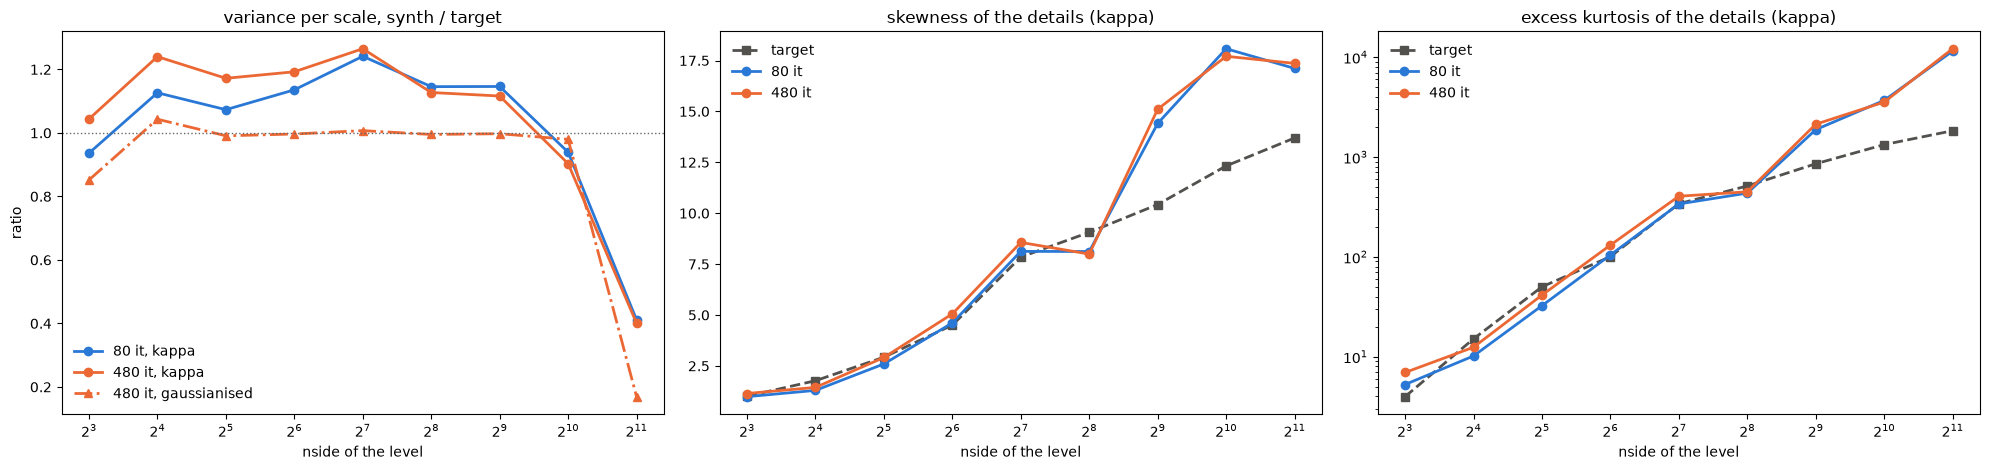

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
for k in ("80 it", "480 it"):
    ax[0].plot(levels, [phys[k][n][0] / phys["target"][n][0] for n in levels], "o-", color=COLORS[k], lw=2, label=f"{k}, kappa")
ax[0].plot(levels, [gauss["480 it"][n][0] / gauss["target"][n][0] for n in levels], "^-.", color=COLORS["480 it"], lw=2,
           label="480 it, gaussianised")
ax[0].axhline(1, color="0.4", ls=":", lw=1)
ax[0].set(title="variance per scale, synth / target", ylabel="ratio")
for col, (i, name, space) in enumerate(((1, "skewness", phys), (2, "excess kurtosis", phys)), start=1):
    for k in ("target", "80 it", "480 it"):
        ax[col].plot(levels, [space[k][n][i] for n in levels], "s--" if k == "target" else "o-", color=COLORS[k], lw=2, label=k)
    ax[col].set(title=f"{name} of the details (kappa)")
ax[2].set_yscale("log")
for a in ax:
    a.set_xscale("log", base=2)
    a.set_xlabel("nside of the level")
    a.legend(frameon=False)
plt.tight_layout()

Reading: in the gaussianised space the synthesis follows the target within 2 % from nside 16 to 1024, but the
finest level (1024 → 2048) has only ~17 % of the target variance. Up-sampling the target to 4096 (bilinear) and
cutting back (mean of 4 children) already removes ~65 % of it; the histogram matching then puts the missing
amplitude into isolated pixels (skewness and kurtosis too high at 512–2048 in κ).

## Small-scale anisotropy

East-west over north-south power of small-scale variations in 30 gnomonic patches (1 = isotropic).

In [22]:
patches = gnomonic_patches(NSIDE, n=256)
for k, m in maps.items():
    r, e = anisotropy(m, patches, n=256)
    print(f"{k:8s} {r:.3f} +- {e:.3f}")

target   1.131 +- 0.095
80 it    0.922 +- 0.084
480 it   0.928 +- 0.071
